# Hit-Generation by Fragment-Based Molecular Optimization

In [37]:
#!pip install pyTDC msal

In [38]:
!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [2]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf

## Library & Seed

### Create molecular library from initial generation (2Seeds) + 100 consecutive leads

In [35]:
#df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
# 
df = pd.read_csv("/home/ec2-user/SageMaker/data/raw/input-mol-inference2/sample_by_prop_from_leads_20250307_c.csv", sep='\t')
df.head(2)

,time,based_on,profile,inchikey,smiles,nearest_project_cmpd,tanimoto_similarity,sampling_dist,ai_h,hsec_total,...,logd_acid,logd_neutral,similarity_max,similarity_mean,similarity_median,MolWt,TPSA,MolLogP,sas,has_isoxazoline
0,2025-03-07 16:21:51,BCS-CN20332,profile aih wo sol,XJJKVTOJFZYGAT-UHFFFAOYSA-N,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1,BCS-DG87418,0.709091,0.3,287.336823,202.215942,...,2.688031,2.843356,715.490845,708.726318,704.912720,327.479218,81.477905,2.447609,3.594501,1.0
1,2025-03-07 16:21:51,BCS-CN20332,profile aih wo sol,SKMFFUNHNPOSET-UHFFFAOYSA-N,Cc1cc(CNC(=O)C2(C)CC(c3cc(F)cc(F)c3)=NO2)on1,BCS-CX72555,1.000000,0.3,279.678040,208.649658,...,2.085713,2.291817,653.023010,658.037354,656.024475,333.580261,76.660912,2.579500,3.284553,1.0


In [36]:
df1 = df.groupby('based_on').head(30)
print(df1.shape)

(60, 28)


In [38]:
df2 = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
df2.drop('score',axis=1,inplace=True)
df2.head(2)

,smiles
0,CCC1CCC1CC(=O)NCCC(=O)OC
1,COC(=O)CCNC(=O)COC(C)(C)C


In [39]:
df3 = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
df3.drop('score',axis=1,inplace=True)
df3.head(2)

,smiles
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1


In [40]:
#clean up
df1 = df1.rename(columns={"ai_h": "AIH", "hsec_total": "HSEC"})
cols = ['smiles'] #,'AIH','HSEC'
df1 = df1[cols].copy()
df1.head(2)

,smiles
0,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1
1,Cc1cc(CNC(=O)C2(C)CC(c3cc(F)cc(F)c3)=NO2)on1


In [41]:
mol_library = pd.concat([df1, df3, df2], join='inner', ignore_index=True) #df1 deleted to see how it works w/o
print(mol_library.shape)
mol_library.head(2)

(633, 1)


,smiles
0,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1
1,Cc1cc(CNC(=O)C2(C)CC(c3cc(F)cc(F)c3)=NO2)on1


In [47]:
#mol_library.to_csv("../../data/interim/genmol/f30_before_optim.csv")

### Seed

In [42]:
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

## Score data with QSAR

In [43]:
# Test 1 with QSAR only
from nv_genmol.by_scorer_new import MoleculeScorer

hsec_scorer = MoleculeScorer.create_scorer( reference_smiles = m1,
                                            use_qsar_hsec=True,
                                            use_qsar_aih=False,
                                            use_qed = False,
                                            use_similarity=False,
                                            similarity_weight=1.0,
                                            similarity_threshold=1.0)

results = hsec_scorer.score(mol_library['smiles'])
len(results.qsar_hsec_scores)

#~now scoring~#
Prediction failed for ID 21: Unknown error
No prediction found for ID 21
Prediction failed for ID 36: Unknown error
No prediction found for ID 36
#~Done scoring~#


633

In [44]:
#create new score column with QSAR scores
mol_library['score'] = results.qsar_hsec_scores # combined_scores / qsar_hsec_scores
mol_library.sort_values(by='score',ascending=False, inplace=True)
print(len(mol_library))
mol_library.head()

633


,smiles,score
15,COCCOC(=O)C[C@H](C)NC(=O)[C@@]1(C)CC(c2cc(Cl)c...,245.72
56,C=CC1(C(=O)NCc2cnn(CC)c2)CC(c2cccc(Cl)c2)=NO1,221.28
13,COC(=O)CCCNC(=O)[C@@]1(SC)CC(c2cc(F)cc(F)c2)=NO1,220.80
42,COC1(C(=O)NCc2cnn(C3CC3)c2)CC(c2cccc(Cl)c2)=NO1,218.03
16,COC(=O)CCCNC(=O)[C@@]1(C)CC(c2cc(Br)cc(Br)c2)=NO1,215.57


In [46]:
mol_library[mol_library['smiles'] == 'COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1']


,smiles,score
0,COC1(C(=O)OCCC#N)CC(c2cc(F)cc(Cl)c2)=NO1,167.43


In [ ]:
mol_library

## Initiate fragment library from known molecules

In [48]:
library = Library(max_fragments = 2000)

In [49]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

In [50]:
#library.fragments
library.export(2)

['c15nccc(C)n1.C2(=O)CC3.CO2.N34.C45',
 'N3C[S+]([O-])c1cc(Cl)cc(Cl)c1.O=C2CC3.O2[Si]']

## Create Oracle

In [51]:
#oracle = Oracle(score = Oracle.RDKitScore('SA'))
# Create an Oracle with HSEC scoring
oracle = Oracle(score=Oracle.HSECScore('hsec', ref_smiles="COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1")) #hsec / comp

In [19]:
# test eval with the original seed 
oracle.evaluate([m1])

#~now scoring~#
#~Done scoring~#


{'COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1': 177.91}

## Generator

In [20]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [21]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['Nc1ncccc1SC1CC1CC(=O)O']

## Optimizer

In [22]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [23]:
data = []

In [26]:
steps=100

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(200)['score'].mean() #50
    std = library.molecules.head(200)['score'].std()  #50
    print(f"BEST {best:.4f} MEAN {mean:.4f} STD {std:.4f}")
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_combined = 1, num_mutate = 50) #10-1-50
    print(f"Step: {i}")
    eval()

BEST 245.7200 MEAN 136.3514 STD 38.7061
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
Step: 0
BEST 245.7200 MEAN 136.9539 STD 38.7127
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
Step: 1
BEST 245.7200 MEAN 137.0598 STD 38.6030
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now scoring~#
#~Done scoring~#
#~now 

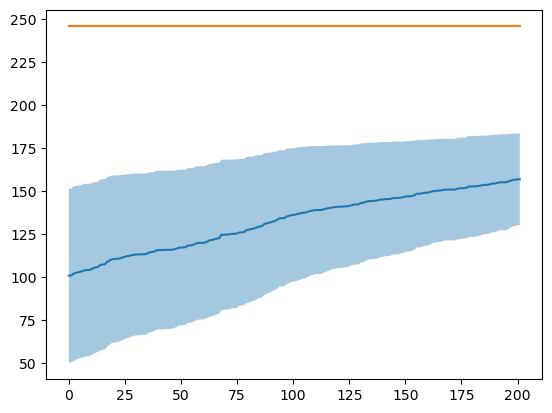

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

In [28]:
df.shape

(202, 3)

# Outputs

In [29]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,C=C(Cl)C1(C(=O)NCCC(=O)OCC)CC(c2cc(F)cc(F)c2)=NO1,245.72
1,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1,221.28
2,CCn1cc(CNC(=O)C2(Cl)CC(c3cccc(Cl)c3)=NO2)cn1,220.80
3,CC(COS(C)(=O)=O)NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2...,218.03
4,CCn1cc(CNC(=O)C2(C)CC(c3cccc(F)c3)=NO2)c(Cl)n1,215.57


In [30]:
len(df_safe)

1184

Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1


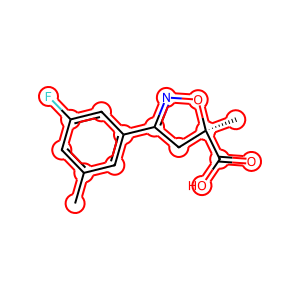

In [31]:
import safe as sf
print(df_safe.iloc[1,0])
sf.to_image(df_safe.iloc[1,0])


In [32]:
len(df_safe)

1184

In [33]:
#df_safe.to_csv('../../data/processed/genmol/UKT_f30_qsar-AIH.csv')

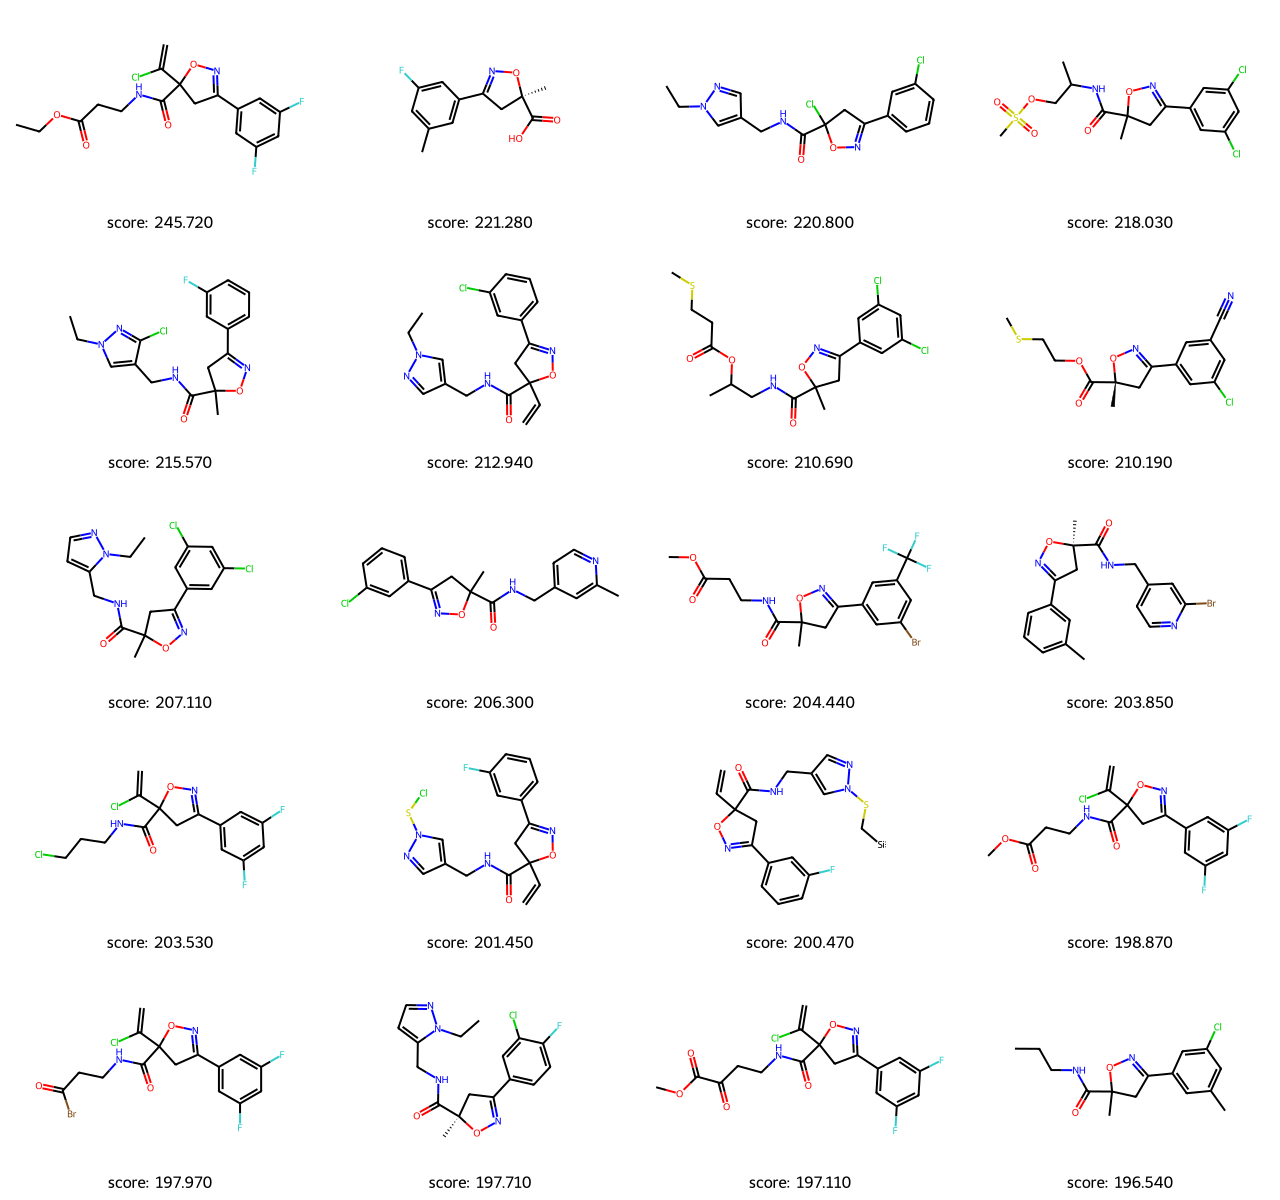

In [34]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)
